# Machine Learning in Python - Project 

Due Friday, December 4th 2026, by 4 pm.

**Include contributors names here!**

## Setup

*Install any packages here, define any functions if needed, and load data.*

In [1]:
# Add any additional libraries or submodules below

# Data libraries
import pandas as pd
import numpy as np

# Plotting libraries
import matplotlib.pyplot as plt
import seaborn as sns

# sklearn modules
import sklearn 

In [2]:
# Load data  
df_avg = pd.read_csv("avg_river_levels.csv")
df_min = pd.read_csv("min_river_levels.csv")
df_max = pd.read_csv("max_river_levels.csv")
df_locs = pd.read_csv("monitoring_locations.csv")

# Introduction

*This section should include a brief introduction to the task and the data (assume this is a report you are delivering to a professional body (e.g. Scottish Government)).*

*State which supervised learning question you are answering.*

*Briefly outline the approaches being used (for both the clustering and your chosen supervised learning task) and the conclusions that you are able to draw.*

# Exploratory Data Analysis and Feature Engineering

*Include a detailed discussion of the data with a particular emphasis on the features of the data that are relevant for the subsequent modeling. Including visualisations of the data is strongly encouraged - all code and plots must also be described in the write up. Think carefully about whether each plot needs to be included in your final draft and the appropriate type of plot and summary for each variable type - your report should include figures but they should be as focused and impactful as possible.*

*You should also split your data into training and testing sets, ideally before you look too much into the features and relationships with the target, as discussed throughout the course.*

*Additionally, this section should also motivate and describe any preprocessing / feature engineering of the data. Pipelines should be used, and feature engineering steps that are performed as part of an sklearn pipeline should be implemented in the following section.*

*All code and figures should be accompanied by text that provides an overview / context to what is being done or presented.*

2. Exploratory Data Analysis and Feature Engineering

Exploratory data analysis (EDA) was carried out to understand the structure, quality and characteristics of the river water-level data before modelling. The analysis focuses on data availability, unusual measurements, temporal patterns and relationships between water-level variables. These findings are used to guide feature selection and preprocessing for the clustering and regression tasks.

2.1 Data overview

The four datasets were first examined to understand their structure, including the number of monitoring records, variables and data types.

In [62]:
# 2.1 Dataset Overview
# Check the dimensions of the four datasets
print("Average water levels:", df_avg.shape)
print("Minimum water levels:", df_min.shape)
print("Maximum water levels:", df_max.shape)
print("Monitoring locations:", df_locs.shape)
# Examine the structure of the average water-level dataset
df_avg.info()
# Display the first five monitoring records of average water-level dataset
df_avg.head()

Average water levels: (392, 4382)
Minimum water levels: (392, 4382)
Maximum water levels: (392, 4382)
Monitoring locations: (392, 5)
<class 'pandas.DataFrame'>
RangeIndex: 392 entries, 0 to 391
Columns: 4382 entries, County to 08/10/2026
dtypes: float64(4379), str(3)
memory usage: 13.1 MB


,County,Station_Name,Observation_ID,05/10/2014,06/10/2014,07/10/2014,08/10/2014,09/10/2014,10/10/2014,13/10/2014,...,29/09/2026,30/09/2026,01/10/2026,02/10/2026,03/10/2026,04/10/2026,05/10/2026,06/10/2026,07/10/2026,08/10/2026
0,aberdeenshire,"Bogie, Redcraig",aberdeenshire__bogie-redcraig__obs1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.133,0.152,0.169,0.143,0.136,0.130,0.126,0.120,0.120,0.120
1,aberdeenshire,"Dee (Grampian), Mar Lodge",aberdeenshire__dee-grampian-mar-lodge__obs1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.721,0.971,0.849,0.799,0.861,0.752,0.727,0.695,0.677,0.669
2,aberdeenshire,"Dee (Grampian), Park",aberdeenshire__dee-grampian-park__obs1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.934,0.973,1.264,0.990,1.054,0.988,0.918,0.887,0.854,0.836
3,aberdeenshire,"Dee (Grampian), Polhollick",aberdeenshire__dee-grampian-polhollick__obs1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.483,0.704,0.683,0.530,0.676,0.530,0.496,0.460,0.438,0.427
4,aberdeenshire,"Dee (Grampian), Woodend",aberdeenshire__dee-grampian-woodend__obs1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.578,0.700,0.861,0.645,0.739,0.642,0.583,0.547,0.514,0.495


The project uses four datasets containing river water-level measurements and monitoring location information across Scotland. The average, minimum and maximum water-level datasets each contain 392 monitoring records and 4,382 columns, including three identification columns and 4,379 daily water-level measurement columns, covering 5 October 2014 to 8 October 2026. Each monitoring record is identified by its county, station name and observation ID. The fourth dataset contains the same 392 observation IDs, together with the latitude and longitude of each monitoring location. From the first five rows of the water-level datasets, several missing values (NaN) were observed, particularly in the earlier dates. This suggests that data completeness needs to be investigated further in the following section.

2.2 Data Quality Assessment

Data quality was assessed to identify potential issues that could affect subsequent modelling. The analysis focuses on missing values, data availability across monitoring records and dates, and consistency between the datasets.

2.2.1 Missing Values

As missing values were observed during the initial data inspection, the number and pattern of missing measurements were examined across the three water-level datasets for further research.

In [3]:
# Count missing values in each water-level dataset
print("Average:", df_avg.isnull().sum().sum())
print("Maximum:", df_max.isnull().sum().sum())
print("Minimum:", df_min.isnull().sum().sum())
# Compare missing-value patterns across the three datasets
print("Average vs Maximum:",
      df_avg.isnull().equals(df_max.isnull()))

print("Average vs Minimum:",
      df_avg.isnull().equals(df_min.isnull()))

Average: 525877
Maximum: 525877
Minimum: 525877
Average vs Maximum: True
Average vs Minimum: True


The results show that all three water-level datasets contain 525,877 missing values, accounting for approximately 30.6% of the measurements. Further checks show that the missing values occur at exactly the same positions across all three datasets. This suggests that some monitoring stations have no recorded minimum, average or maximum water levels on certain days.

2.2.2 Missing Values by Monitoring Station

To further investigate missing data, the number of available observations was calculated for each monitoring record. This helps identify which monitoring records have relatively complete data and which have substantial gaps. Data completeness is important for both clustering and regression, as missing observations may affect feature calculations and model training.

In [6]:
# Count missing values for each monitoring record
missing_records = df_avg.iloc[:, 3:].isna().sum(axis=1)
# Calculate the number of valid observations
valid_records = 4379 - missing_records
# Create a table showing data availability
station_coverage = df_avg[["Station_Name", "Observation_ID"]].copy()
station_coverage["Valid_Records"] = valid_records
station_coverage["Missing_Records"] = missing_records
# Display records with the most valid observations
print("Monitoring records with the most valid observations:")
display(station_coverage[["Station_Name", "Valid_Records", "Missing_Records"]]
        .sort_values("Valid_Records", ascending=False).head(5))

# Display records with the fewest valid observations
print("Monitoring records with the fewest valid observations:")
display(station_coverage[["Station_Name", "Valid_Records", "Missing_Records"]]
        .sort_values("Valid_Records").head(5))

Monitoring records with the most valid observations:


,Station_Name,Valid_Records,Missing_Records
301,"River Tweed, Sprouston",4373,6
122,"River Esk, Canonbie (SEPA Site)",4331,48
348,Kinlochbervie,3376,1003
43,Tobermory,3376,1003
44,Tobermory,3376,1003


Monitoring records with the fewest valid observations:


,Station_Name,Valid_Records,Missing_Records
20,"Elliot Water, Kelly Den - Arbilot",452,3927
189,"Carron, Carron upstream (Stonehaven)",480,3899
285,"Newhall Burn, Newhall Bridge",570,3809
383,"Dargall Lane, Dargall Lane",572,3807
25,"Lunan Water, Murton",647,3732


The results show that data availability varies considerably between monitoring records. River Tweed at Sprouston has the most complete record, with 4,373 valid observations and only 6 missing values, followed by River Esk at Canonbie (SEPA Site), with 4,331 valid observations and 48 missing values. In contrast, Elliot Water at Kelly Den–Arbilot has the fewest valid observations (452), followed by Carron upstream (480), Newhall Burn (570), Dargall Lane (572) and Lunan Water (647). These monitoring records have more than 3,700 missing observations each. This difference in data completeness needs to be considered during preprocessing, as records with limited observations may affect feature calculations and the reliability of clustering and regression models.

2.2.3  Data Coverage Over Time

In addition to differences between monitoring records, data availability was examined over time to identify periods with limited observations. This is important for understanding the historical coverage of the datasets and the potential impact of missing data on model development.

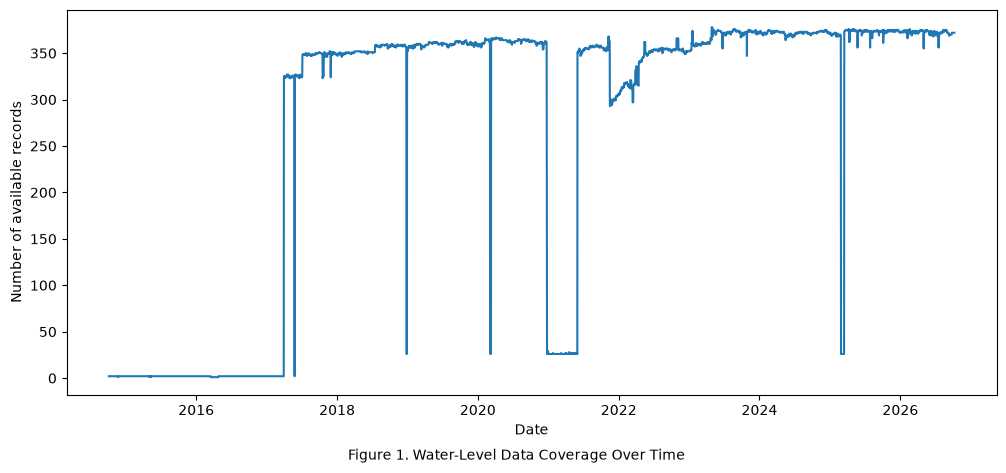

In [8]:
# Count available records for each date
daily_coverage = 392 - df_avg.iloc[:, 3:].isna().sum()
daily_coverage
# Count available monitoring records for each date
daily_coverage = 392 - df_avg.iloc[:, 3:].isna().sum()
# Convert date labels to datetime
dates = pd.to_datetime(daily_coverage.index, dayfirst=True)
# Plot data coverage over time
plt.figure(figsize=(12, 5))
plt.plot(dates, daily_coverage.values)
plt.xlabel("Date")
plt.ylabel("Number of available records")
# Add figure caption below the plot
plt.figtext(0.5, -0.02,
            "Figure 1. Water-Level Data Coverage Over Time",
            ha="center")
plt.show()

Figure 1 shows that data coverage changed considerably over time. Between 2014 and early 2017, only around 1–2 monitoring records were available per day. Coverage then increased sharply to approximately 320 records in 2017 and gradually reached around 370 records in later years. However, several sudden drops in data availability can be observed, particularly around 2019–2021 and 2025. These gaps suggest that the number of available monitoring records was not consistent throughout the study period. This needs to be considered during preprocessing and model development, as periods with limited observations may affect the analysis of historical water-level patterns.

2.2.4 Data Consistency and Duplicate Records

After examining missing values and data coverage, the datasets were checked for duplicate records and consistency. This is important because the average, minimum and maximum water-level measurements must correspond to the same monitoring records and dates to ensure accurate analysis and modelling.
After examining missing values and data coverage, the datasets were checked for duplicate records and consistency. This is important because the average, minimum and maximum water-level measurements must correspond to the same monitoring records and dates to ensure accurate analysis and modelling.

In [9]:
# Check duplicate rows in each dataset
print("Average duplicate rows:", df_avg.duplicated().sum())
print("Minimum duplicate rows:", df_min.duplicated().sum())
print("Maximum duplicate rows:", df_max.duplicated().sum())
# Check duplicate Observation_ID values
print("Average duplicate IDs:", df_avg["Observation_ID"].duplicated().sum())
print("Minimum duplicate IDs:", df_min["Observation_ID"].duplicated().sum())
print("Maximum duplicate IDs:", df_max["Observation_ID"].duplicated().sum())
# Check consistency of monitoring record IDs
print("Average vs Minimum IDs:",
      df_avg["Observation_ID"].equals(df_min["Observation_ID"]))
print("Average vs Maximum IDs:",
      df_avg["Observation_ID"].equals(df_max["Observation_ID"]))
# Check consistency of date columns
print("Average vs Minimum dates:",
      df_avg.columns[3:].equals(df_min.columns[3:]))
print("Average vs Maximum dates:",
      df_avg.columns[3:].equals(df_max.columns[3:]))

Average duplicate rows: 0
Minimum duplicate rows: 0
Maximum duplicate rows: 0
Average duplicate IDs: 0
Minimum duplicate IDs: 0
Maximum duplicate IDs: 0
Average vs Minimum IDs: True
Average vs Maximum IDs: True
Average vs Minimum dates: True
Average vs Maximum dates: True


The results show that no duplicate rows or observation IDs were found in any of the three water-level datasets. Further checks confirmed that all three datasets contain the same observation IDs and date columns in the same order. This indicates that the average, minimum and maximum water-level measurements are aligned by monitoring record and date, allowing them to be used together in subsequent analyses.

2.3  Chronological Data Splitting

The water-level datasets were divided chronologically into training, validation and test sets. This approach was used because the regression task involves predicting future water levels using historical observations. Splitting the data by date helps prevent information from future observations being used during model training. A training-to-validation ratio of approximately 9:1 was used for the historical data. The training set covers 5 October 2014 to 31 August 2025, while the validation set covers 1 September 2025 to 31 August 2026. A full 12-month period was selected for validation to include all four seasons, allowing the models to be evaluated under different seasonal water-level conditions. The validation set is used for model tuning and comparison. The test set covers 1 September 2026 to 8 October 2026 and is used to evaluate predictions against available observations. Although the project aims to predict water levels from September to November 2026, the available datasets only contain observations up to 8 October 2026. Therefore, only part of the prediction period can be evaluated using the provided data.

In [11]:
# Split average water-level data
avg_train = df_avg.loc[:, "05/10/2014":"31/08/2025"]
avg_val = df_avg.loc[:, "01/09/2025":"31/08/2026"]
avg_test = df_avg.loc[:, "01/09/2026":"08/10/2026"]
# Split minimum water-level data
min_train = df_min.loc[:, "05/10/2014":"31/08/2025"]
min_val = df_min.loc[:, "01/09/2025":"31/08/2026"]
min_test = df_min.loc[:, "01/09/2026":"08/10/2026"]
# Split maximum water-level data
max_train = df_max.loc[:, "05/10/2014":"31/08/2025"]
max_val = df_max.loc[:, "01/09/2025":"31/08/2026"]
max_test = df_max.loc[:, "01/09/2026":"08/10/2026"]
# Check the number of observations in each split
print("Training:", avg_train.shape)
print("Validation:", avg_val.shape)
print("Test:", avg_test.shape)

Training: (392, 3976)
Validation: (392, 365)
Test: (392, 38)


The results confirm that the three water-level datasets were successfully divided into training, validation and test sets. Each set retains all 392 monitoring records, with 3,976 date columns for training, 365 for validation and 38 for testing. The same date ranges were applied to the average, minimum and maximum water-level datasets to maintain consistency across the three measurements.

2.4.1 Descriptive Statistics and Distributions

Descriptive statistics were calculated using the training data to understand how water levels vary between monitoring records. The analysis focuses on two measurements: the mean and standard deviation of average water levels for each monitoring record. The mean represents the typical water level at each monitoring record, while the standard deviation measures how much water levels vary over time. A higher standard deviation indicates greater fluctuations in water levels. These statistics help describe differences between monitoring records and may also be useful features for clustering.

In [16]:
# Calculate mean water level for each monitoring record
station_mean = avg_train.mean(axis=1)
# Calculate standard deviation for each monitoring record
station_std = avg_train.std(axis=1)
# Summarise the results
print("Mean water-level statistics:")
print(station_mean.describe())
print("\nWater-level standard deviation statistics:")
print(station_std.describe())

Mean water-level statistics:
count    392.000000
mean       5.422878
std       50.281696
min     -212.641379
25%        0.357804
50%        0.509252
75%        0.753991
max      749.436484
dtype: float64

Water-level standard deviation statistics:
count      392.000000
mean       179.966579
std       1367.655386
min          0.023134
25%          0.164870
50%          0.228891
75%          0.328298
max      21437.313974
dtype: float64


The results show considerable differences in water-level statistics between monitoring records. The median of the station-level mean water levels is approximately 0.509, while the overall mean is much higher at 5.423. Similarly, the median station-level standard deviation is only 0.229, compared with an overall mean of 179.967. These large differences between the means and medians suggest that a small number of extreme values may be strongly influencing the results. Therefore, further investigation of unusual water-level measurements is needed before using these statistics as features for clustering or regression.

2.4.2 Data Visualisation

To further investigate the differences observed in the descriptive statistics, histograms were used to examine the distributions of station-level mean water levels and standard deviations. These plots help identify where most monitoring records are concentrated and whether extreme values are present.

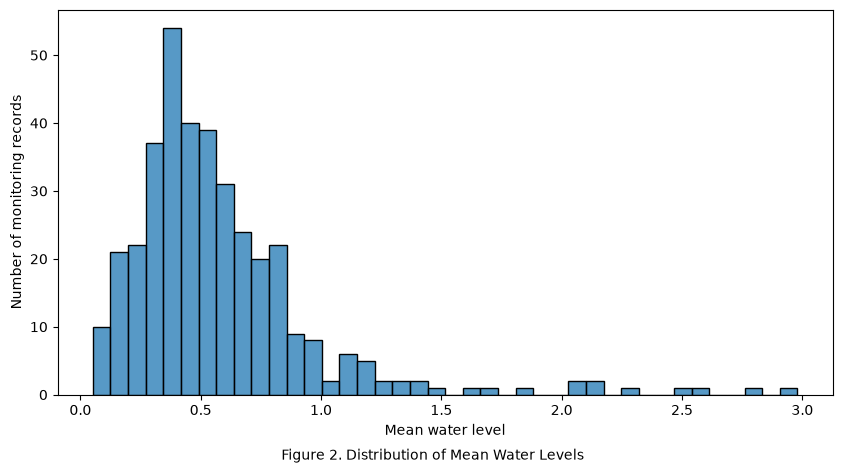

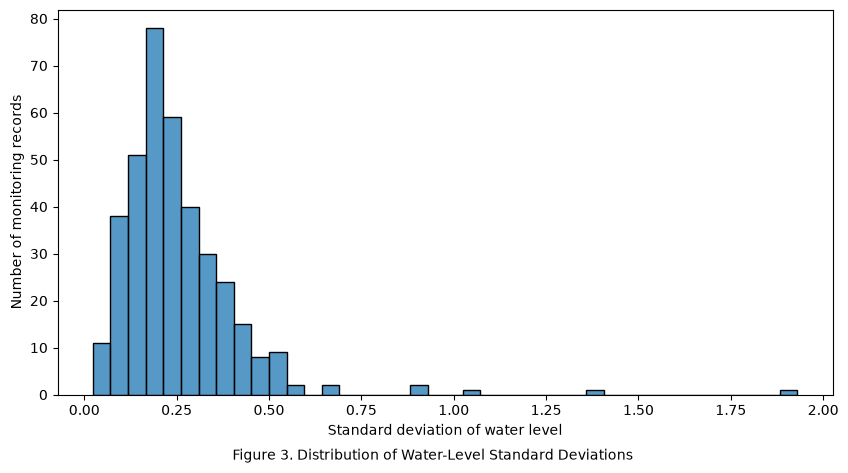

In [20]:
# Distribution of station-level mean water levels
plt.figure(figsize=(10, 5))
sns.histplot(station_mean[(station_mean >= -1) & (station_mean <= 3)],
             bins=40)
plt.xlabel("Mean water level")
plt.ylabel("Number of monitoring records")

plt.figtext(0.5, -0.02,
            "Figure 2. Distribution of Mean Water Levels",
            ha="center")
plt.show()
# Distribution of station-level standard deviations
plt.figure(figsize=(10, 5))
sns.histplot(station_std[(station_std >= 0) & (station_std <= 2)],
             bins=40)
plt.xlabel("Standard deviation of water level")
plt.ylabel("Number of monitoring records")
plt.figtext(0.5, -0.02,
            "Figure 3. Distribution of Water-Level Standard Deviations",
            ha="center")
plt.show()

Figures 2 and 3 show that both distributions are right-skewed. Most monitoring records have mean water levels between approximately 0.2 and 0.8, while their standard deviations are mainly concentrated between 0.1 and 0.4. However, a small number of monitoring records have considerably higher values, indicating differences in typical water levels and variability between monitoring records. The histograms focus on the main distributions, excluding extreme values outside the displayed ranges. These extreme values remain in the original data and will be investigated further in the next section.

2.5 Outlier Investigation

The descriptive statistics and histograms revealed several extreme water-level values that may be affecting the results. To investigate these observations, measurements above 100 or below −100 were identified in the training data. These thresholds were chosen as preliminary screening limits to highlight particularly extreme values, rather than as scientifically established outlier boundaries. The flagged observations will be investigated further before deciding whether any data cleaning is necessary.

In [21]:
# Count unusually high water-level measurements
high_values = (avg_train > 100).sum().sum()
# Count unusually low water-level measurements
low_values = (avg_train < -100).sum().sum()
print("Measurements above 100:", high_values)
print("Measurements below -100:", low_values)
print("Total extreme measurements:", high_values + low_values)

Measurements above 100: 49
Measurements below -100: 26
Total extreme measurements: 75


The initial screening identified 75 extreme measurements in the training data, including 49 values above 100 and 26 values below −100. These values were flagged for further investigation rather than immediately treated as errors, since the thresholds were only used to identify potentially unusual observations.

In [30]:
# Count extreme measurements for each monitoring record
extreme_counts = ((avg_train > 100) | (avg_train < -100)).sum(axis=1)
# Create a table of monitoring records
extreme_stations = df_avg[["Station_Name", "Observation_ID"]].copy()
extreme_stations["Extreme_Values"] = extreme_counts
# Show monitoring records containing extreme measurements
display(extreme_stations[extreme_stations["Extreme_Values"] > 0]
        .sort_values("Extreme_Values", ascending=False))

,Station_Name,Observation_ID,Extreme_Values
182,"Spey, Spey Dam",inverness__spey-spey-dam__obs1,23
329,"Endrick Water, Graystone Bridge",stirling-and-falkirk__endrick-water-graystone-...,10
45,"Annick Water, Chapeltoun Gauging Station",ayrshire-and-arran__annick-water__obs1,8
245,"Leven (Fife), Loch Leven Sluices",perth-and-kinross__leven-fife-loch-leven-sluic...,6
55,"Garnock, Kilbirnie",ayrshire-and-arran__garnock-kilbirnie__obs1,4
170,"Lochy (Lochaber), Gairlochy",inverness__lochy-lochaber__obs1,4
335,"Loch Ard, Loch Ard",stirling-and-falkirk__forth-loch-ard__obs1,3
16,"Urie, Pitcaple",aberdeenshire__urie-pitcaple__obs1,2
110,"Esk (Solway), Langholm Bridge",dumfries__esk-solway-langholm-bridge__obs1,2
326,"Duchray Water, Renagour Bridge",stirling-and-falkirk__duchray-water__obs1,2


The 75 extreme measurements were found across 20 monitoring records, with most concentrated in a small number of records. Spey at Spey Dam contains the highest number (23), followed by Endrick Water at Graystone Bridge (10), Annick Water at Chapeltoun Gauging Station (8) and Leven at Loch Leven Sluices (6). Together, these four records account for 47 of the 75 extreme measurements. This suggests that unusually large or small measurements are concentrated in certain monitoring records rather than being evenly distributed across the dataset.

In [39]:
# Select monitoring records containing extreme measurements
extreme_records = avg_train.loc[extreme_counts > 0]
# Create a table of minimum and maximum values
extreme_summary = df_avg.loc[extreme_counts > 0, ["Station_Name"]].copy()
extreme_summary["Minimum"] = extreme_records.min(axis=1)
extreme_summary["Maximum"] = extreme_records.max(axis=1)
# Display the results
display(extreme_summary)

,Station_Name,Minimum,Maximum
16,"Urie, Pitcaple",0.000,192.294
45,"Annick Water, Chapeltoun Gauging Station",0.011,109589.604
55,"Garnock, Kilbirnie",-7.905,157895.392
61,"Kilmarnock Water, Howard Park",0.017,170213.366
100,"Water of Leith, Colinton",0.016,41666.821
110,"Esk (Solway), Langholm Bridge",0.034,62500.697
121,"Nith, Whitesands",-0.004,83333.680
125,"Aber Burn, Lagganbeg",0.015,20833.742
134,"Loch Lomond, Ross Priory",-24.326,91961.524
155,"Dulnain, Inverlaidnan Bridge",0.046,41667.358


Further investigation revealed unusually large positive and negative measurements across the 20 flagged monitoring records. For example, Kinlochewe Lodge recorded a maximum value of 999,999.999, while Endrick Water at Graystone Bridge reached 307,692.995. In contrast, Blackwater of Dee at Loch Dee Outlet recorded a minimum of −190,475.436, and Spey Dam recorded −119,562.593. These extreme measurements may explain the unusually high means and standard deviations observed in the descriptive statistics. However, further investigation is needed to determine whether they represent genuine observations or potential data errors before deciding how to handle them during preprocessing.

To further investigate data quality, the minimum, average and maximum water-level measurements were compared for each monitoring record and date. Under normal conditions, the minimum water level should not exceed the average, and the average should not exceed the maximum. Any violations of this relationship may indicate potential data inconsistencies.

In [35]:
# Check whether minimum exceeds average water level
min_avg_violations = (min_train > avg_train).sum().sum()
# Check whether average exceeds maximum water level
avg_max_violations = (avg_train > max_train).sum().sum()
print("Minimum > Average:", min_avg_violations)
print("Average > Maximum:", avg_max_violations)

Minimum > Average: 0
Average > Maximum: 0


The consistency check found no cases where the minimum water level exceeded the average or where the average exceeded the maximum. This indicates that the three measurements follow the expected ordering for the available observations. However, this does not confirm that all measurements are accurate, as some extreme values may still represent data errors.

2.6 Temporal and Seasonal Patterns

This section examines how river water levels change over time and across different seasons. The aim is to identify temporal and seasonal patterns that may provide useful features for clustering and regression.
For clustering, seasonal patterns may help distinguish monitoring records with different water-level behaviour. For regression, these patterns may suggest useful time-related features, such as the month of the year, for predicting future water levels. The analysis focuses on identifying potential features using the training data. 

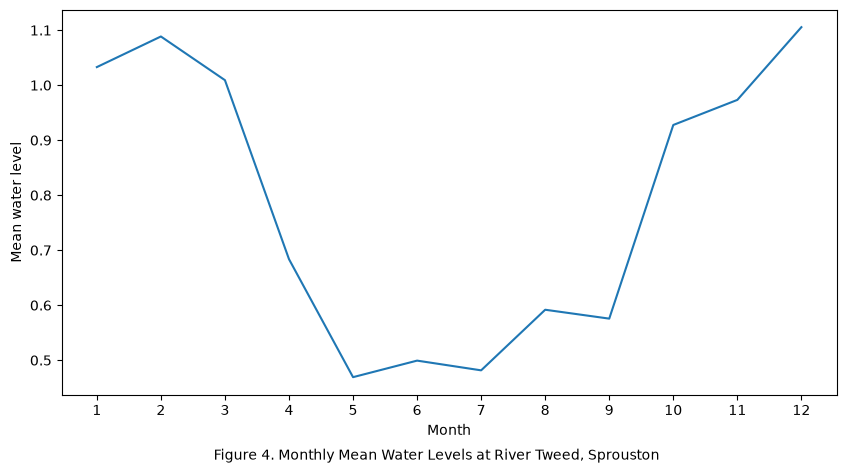

In [36]:
# Select water-level data for River Tweed, Sprouston
sprouston = avg_train.loc[308]
# Convert dates into datetime
dates = pd.to_datetime(avg_train.columns, dayfirst=True)
# Create a DataFrame with month and water level
monthly_levels = pd.DataFrame({
    "Month": dates.month,
    "Water_Level": sprouston.values
})
# Calculate mean water level for each month
monthly_mean = monthly_levels.groupby("Month")["Water_Level"].mean()
# Plot monthly mean water levels
plt.figure(figsize=(10, 5))
plt.plot(monthly_mean.index, monthly_mean.values)
plt.xlabel("Month")
plt.ylabel("Mean water level")
plt.xticks(range(1, 13))
# Add figure caption below the plot
plt.figtext(0.5, -0.02,
            "Figure 4. Monthly Mean Water Levels at River Tweed, Sprouston",
            ha="center")
plt.show()

Figure 4 shows a clear seasonal pattern in average water levels at River Tweed, Sprouston. Water levels are generally higher during winter, reaching approximately 1.1 in December and February, and lower during late spring and summer, with the lowest value of around 0.47 in May. Levels then increase again during autumn. This suggests that seasonal information, such as the month of the year, may be a useful feature for regression. Seasonal variation may also help distinguish monitoring records with different water-level patterns in clustering. However, this result is based on one monitoring record and may not represent all monitoring locations.

2.7 Relationships Between Variables

The relationships between minimum, average and maximum water levels were examined using correlation analysis. This helps determine whether the three measurements provide similar or different information.
For clustering, highly correlated features may contain overlapping information and influence the grouping of monitoring records. For regression, understanding these relationships may help identify useful historical water-level features for predicting future observations. The analysis was conducted using the training data to avoid information leakage.

In [38]:
# Compare water-level measurements at Tweed, Sprouston
water_level_comparison = pd.DataFrame({
    "Minimum": min_train.loc[308].values,
    "Average": avg_train.loc[308].values,
    "Maximum": max_train.loc[308].values
})
# Calculate the correlation matrix
display(water_level_comparison.corr())

,Minimum,Average,Maximum
Minimum,1.000000,0.944455,0.879483
Average,0.944455,1.000000,0.970063
Maximum,0.879483,0.970063,1.000000


The correlation analysis for Tweed, Sprouston shows strong positive relationships between minimum, average and maximum water levels. The strongest correlation is between average and maximum levels (0.970), followed by minimum and average levels (0.944) and minimum and maximum levels (0.879).These results suggest that the three measurements contain closely related information. For clustering, highly correlated features may provide overlapping information, while for regression, historical minimum and maximum water levels may be useful predictors of future water levels. However, these relationships are based on one monitoring record and may differ across other locations.

2.8 Feature Engineering and Preprocessing Decisions

Based on the EDA findings, several preprocessing and feature engineering steps were identified for clustering and regression. Approximately 30.6% of the water-level measurements are missing, and 75 extreme measurements were identified in the training data. These issues need to be considered during preprocessing to reduce their potential impact on model performance.
For clustering, historical mean water levels, standard deviations and seasonal patterns may be useful features for grouping monitoring records with similar characteristics. For regression, historical water levels and time-related features, such as the month of the year, may help predict future water levels. The correlation analysis also suggests that some water-level measurements contain overlapping information, which should be considered when selecting features.

# Model Fitting and Tuning

*In this section you should detail and motivate your choice of model and describe the process used to refine, tune, and fit that model. You are encouraged to explore different models but you should NOT include a detailed narrative or code of all of these attempts. At most this section should very briefly mention the methods explored and why they were rejected - most of your effort should go into describing the final model you are using and your process for tuning and validating it.*

*This section should include the full implementation of your final model, including all necessary validation. All displayed figures should be described and referenced in the text.*

*You should also include a baseline model of your choice and provide a comparison of your model with the baseline model on the test data. You should briefly describe the baseline model considered.*

# Interpretation, Discussion & Conclusions

*In this section you should provide a general overview of your final clustering and of your final supervised learning model, its performance, and reliability. You should discuss what the implications of your models are in terms of the included features, estimated parameters and relationships, predictive performance, and anything else you think is relevant.*

*This should be written with a target audience of a government official, who understands the monitoring of river levels but may only have university level mathematics (not necessarily postgraduate statistics or machine learning). Your goal should be to highlight to this audience how your model can useful. You should also discuss potential limitations or directions of future improvement of your model.*

*Finally, you should include recommendations on factors that may influence the classification of flood events OR the prediction of future water levels (depending on which question you are answering), which may be useful for the government officials to improve their understanding of floods or water level forecasting, and potentially assist in the development of effective river management and interventions.*

*Keep in mind that a negative result, i.e. a model that does not work well predictively, that is well explained and justified in terms of why it failed will likely receive higher marks than a model with strong predictive performance but with poor or incorrect explanations / justifications.*

# Generative AI statement

*Include a statement on if and how generative AI was used in the project and report.*

# References

*Include a list of all references cited in the text.*

In [60]:
# Run the following to render to PDF
!jupyter nbconvert --to pdf project.ipynb

[NbConvertApp] Converting notebook project.ipynb to pdf
[NbConvertApp] Support files will be in project_files/
[NbConvertApp] Making directory ./project_files
[NbConvertApp] Writing 109128 bytes to notebook.tex
[NbConvertApp] Building PDF
[NbConvertApp] Running xelatex 3 times: ['xelatex', 'notebook.tex', '-quiet']
[NbConvertApp] Running bibtex 1 time: ['bibtex', 'notebook']
[NbConvertApp] WARNING | bibtex had problems, most likely because there were no citations
[NbConvertApp] PDF successfully created
[NbConvertApp] Writing 336900 bytes to project.pdf
